In [3]:
%run ../Preprocessing/Preprocessing.ipynb

Tried LBFGS as the solver, didn't work

--------------PREPROCESSING:  ORIGINAL --------------
Time Taken ( Baseline (Median) ):  0.061652183532714844


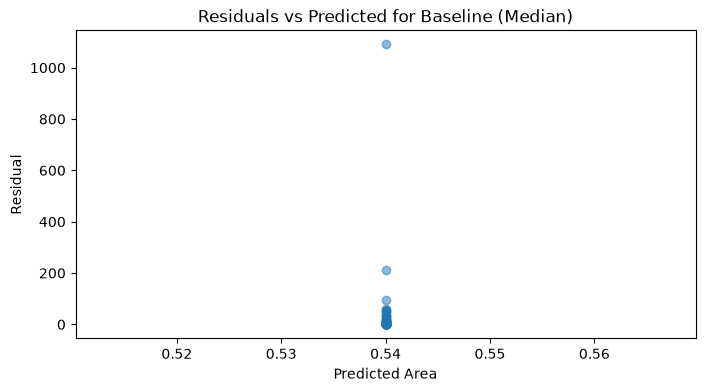

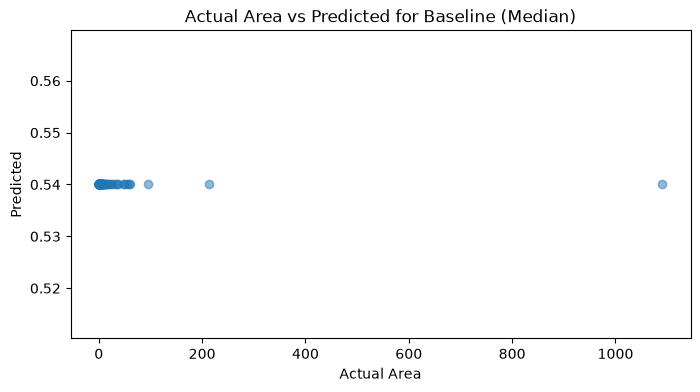

58
0.7688863176905583
Time Taken ( Base Neural Network ):  0.20873308181762695


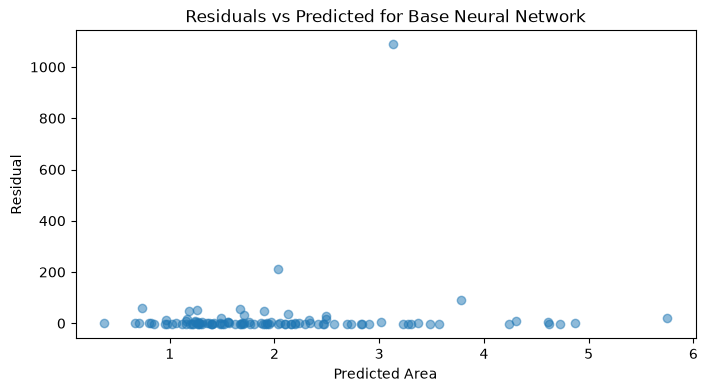

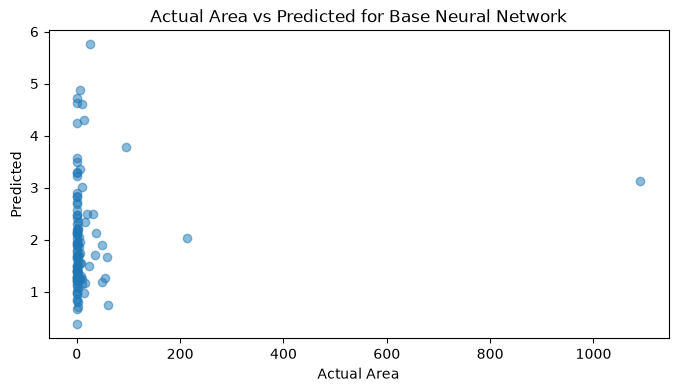

54
0.7687283048554666
Time Taken ( More layers ):  1.3237438201904297


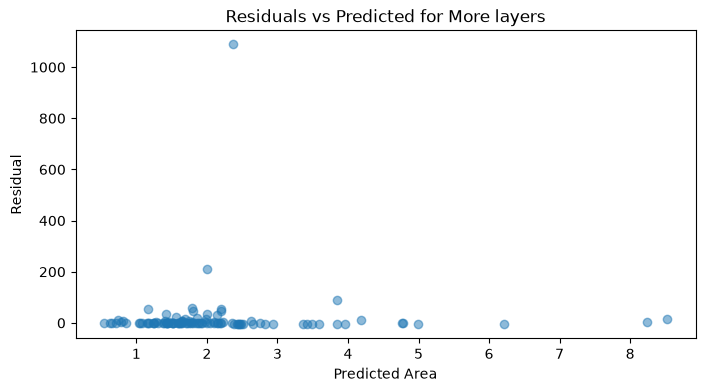

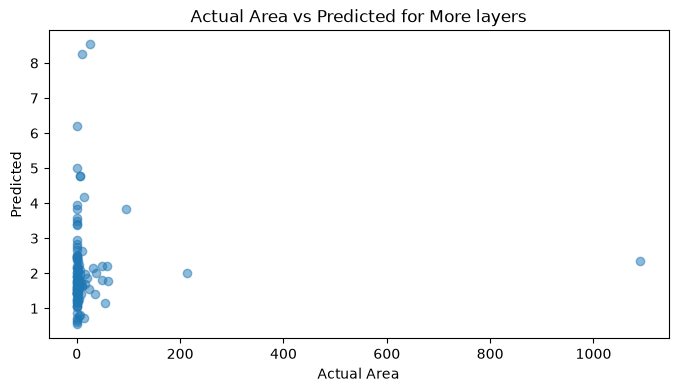

472
0.8041852913807945
Time Taken ( Sgd ):  1.497049331665039


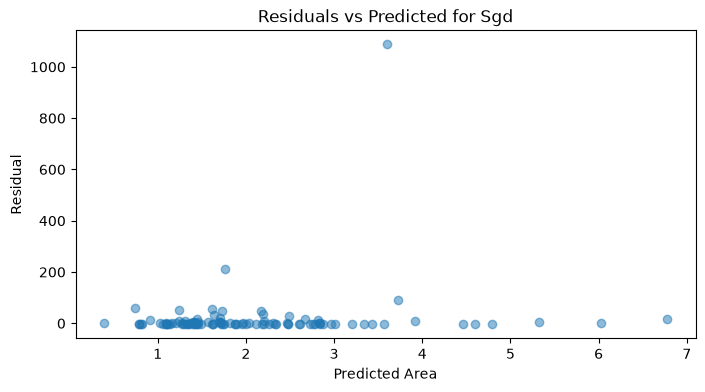

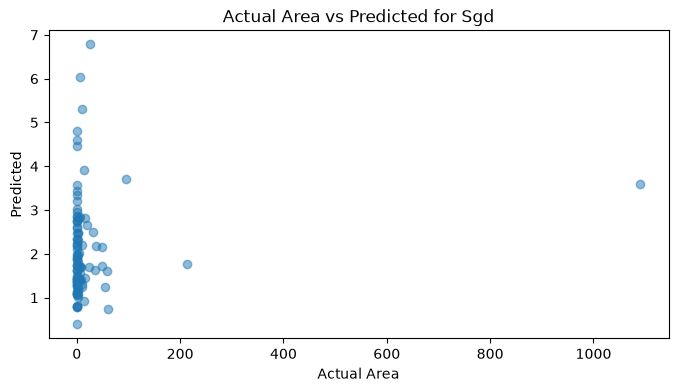

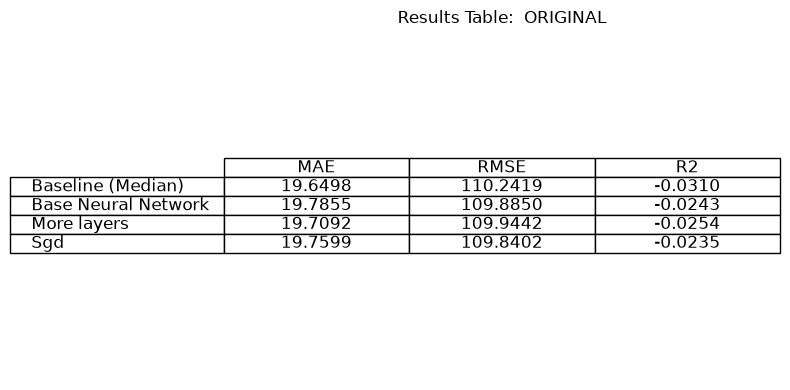

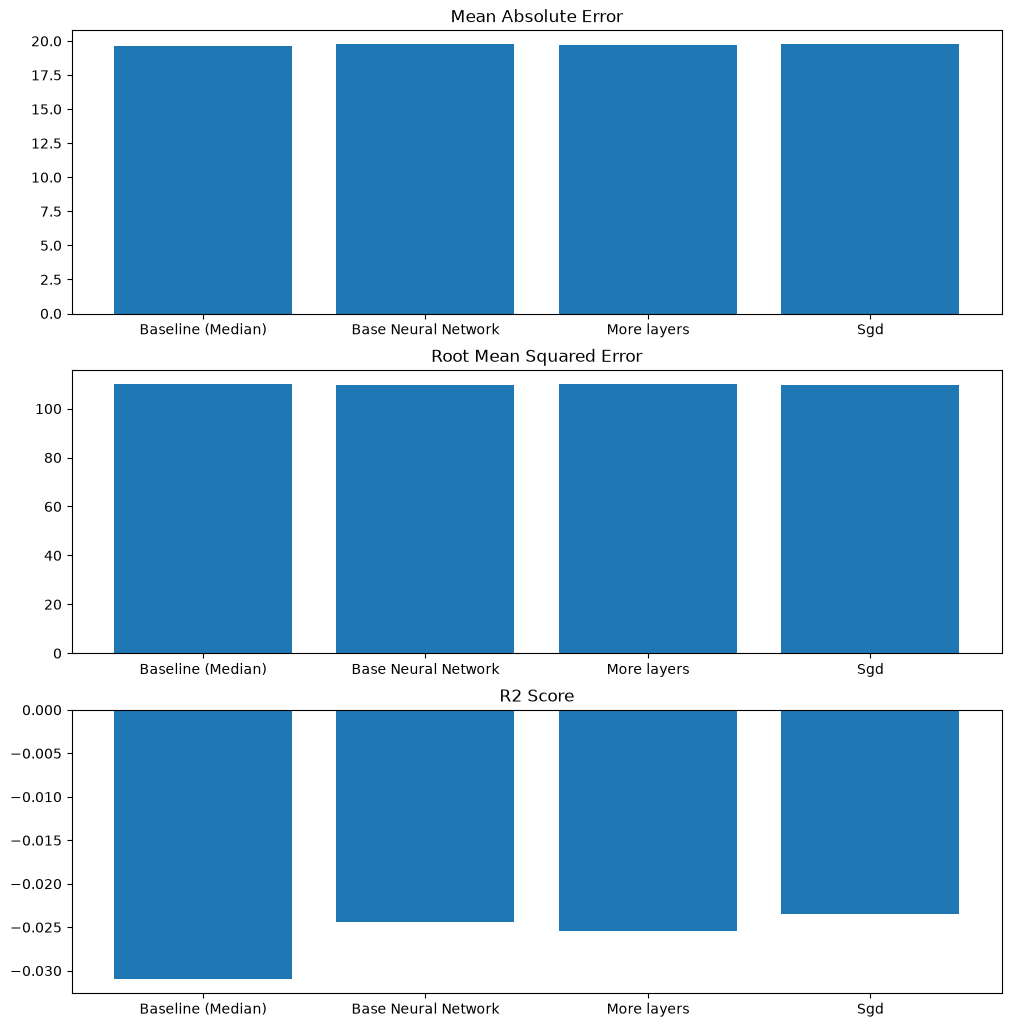

--------------PREPROCESSING:  ALL --------------
Time Taken ( Baseline (Median) ):  0.0424189567565918


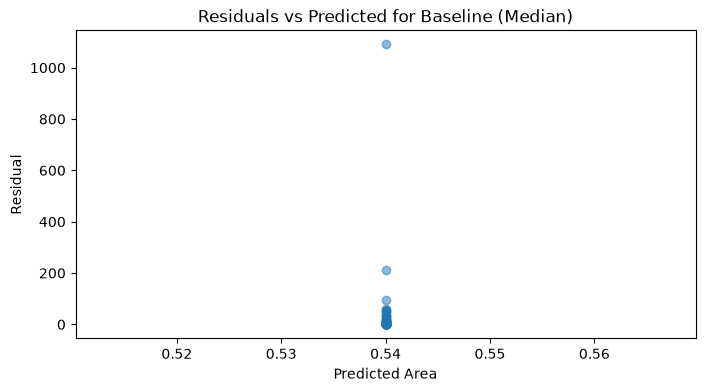

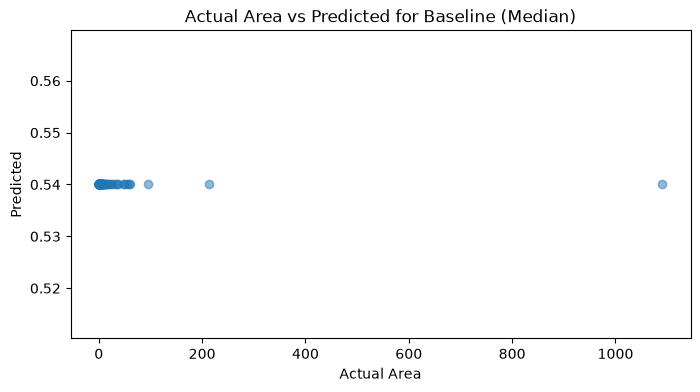

28
0.9505586849608717
Time Taken ( Base Neural Network ):  0.11693263053894043


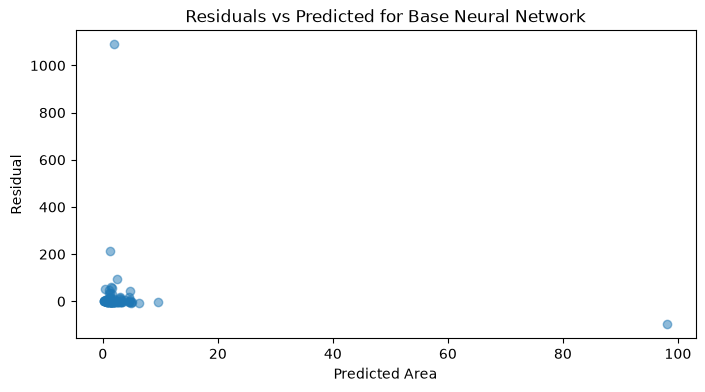

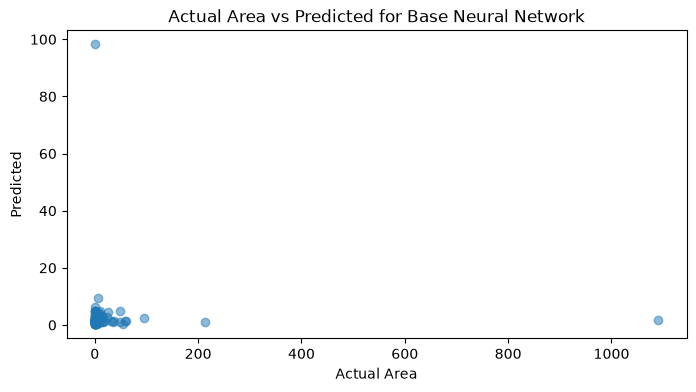

26
0.7899443863604481
Time Taken ( More layers ):  0.8029079437255859


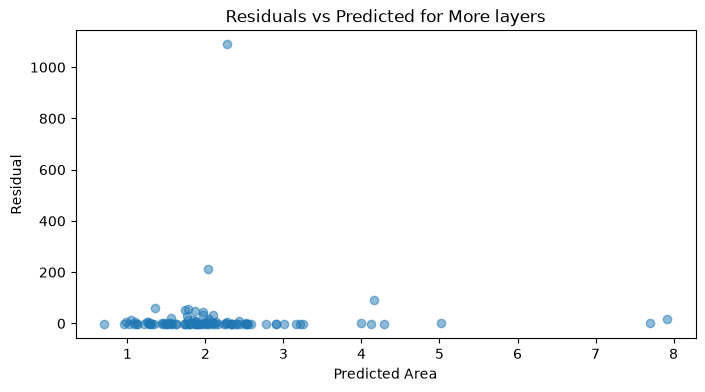

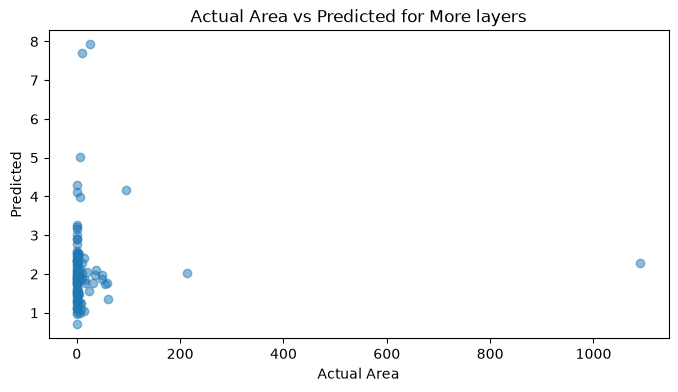

53
0.9537539378393073
Time Taken ( Sgd ):  0.17488622665405273


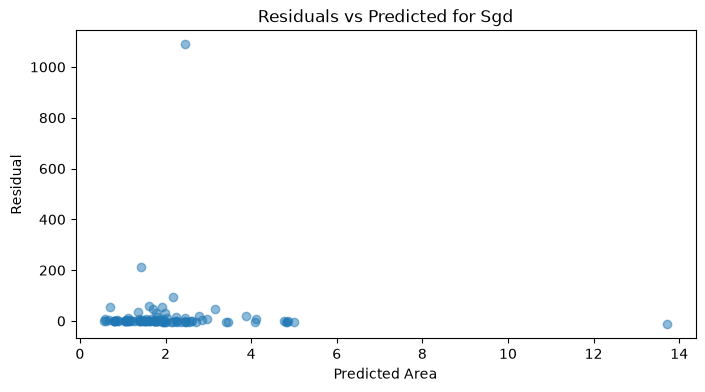

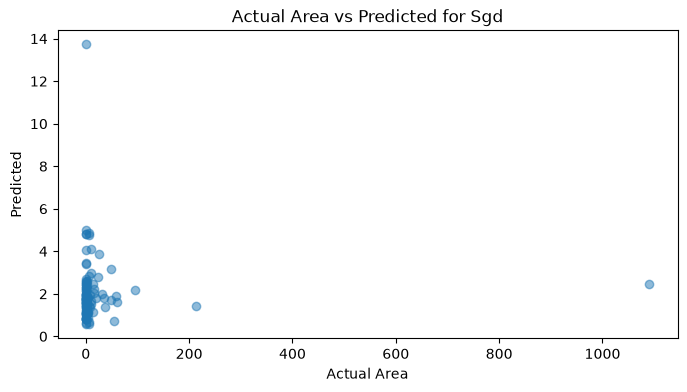

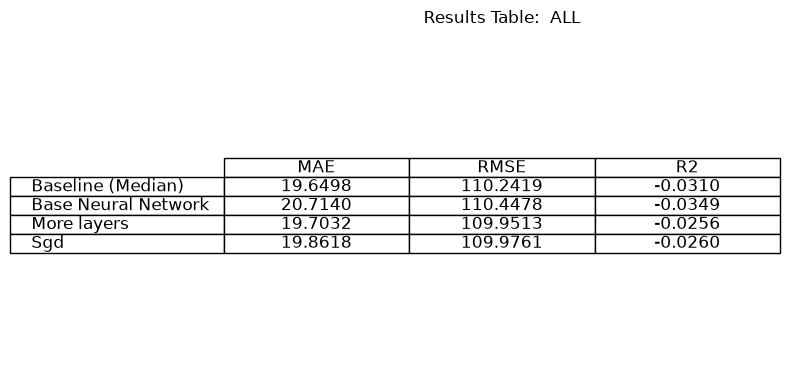

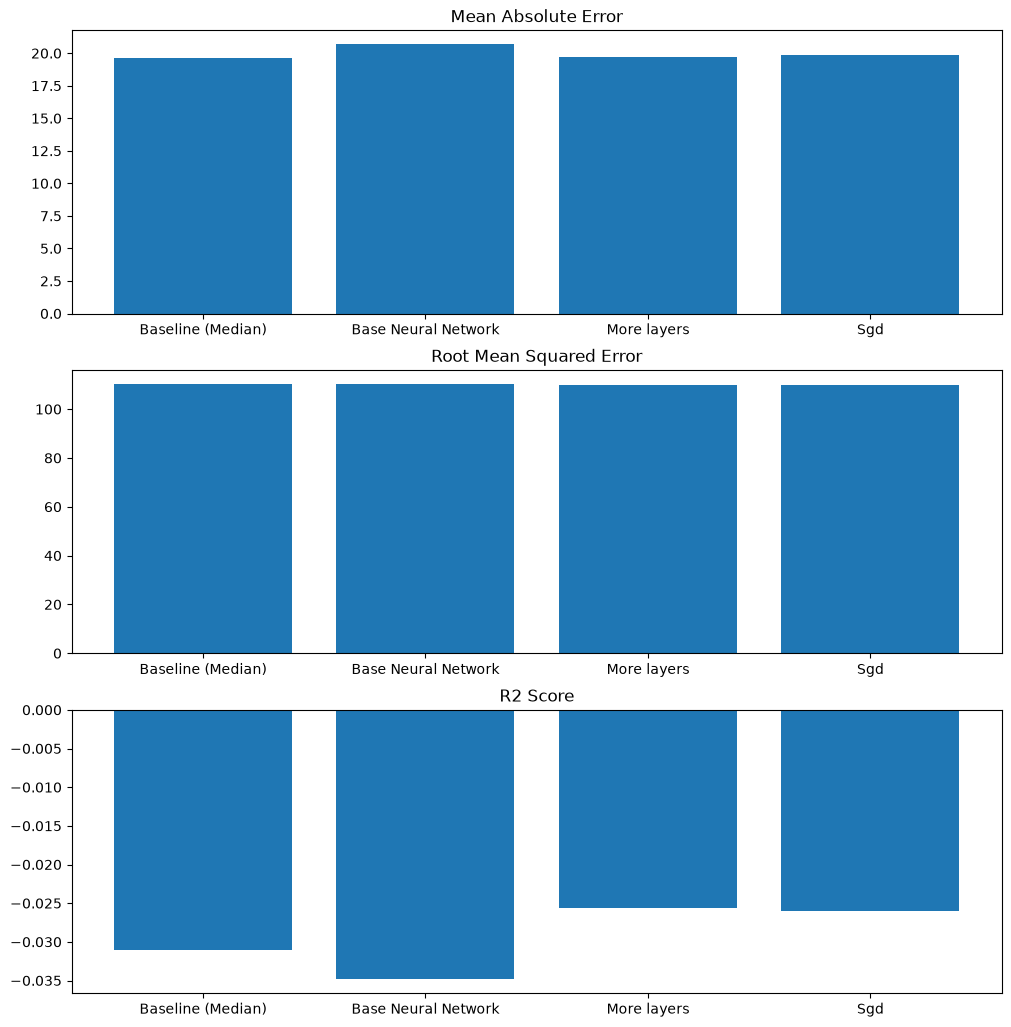

--------------PREPROCESSING:  FIRE WEATHER INDEX ONLY --------------
Time Taken ( Baseline (Median) ):  0.024449825286865234


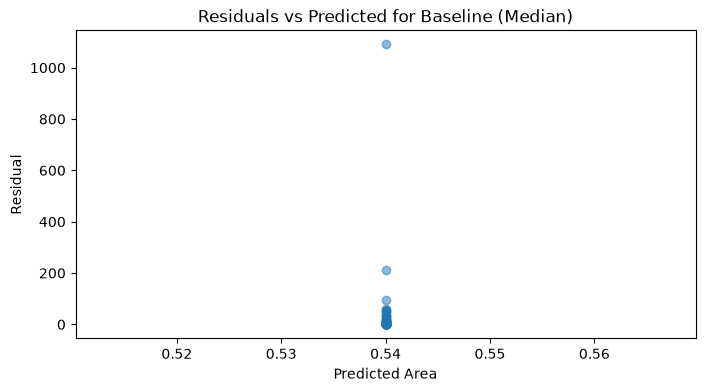

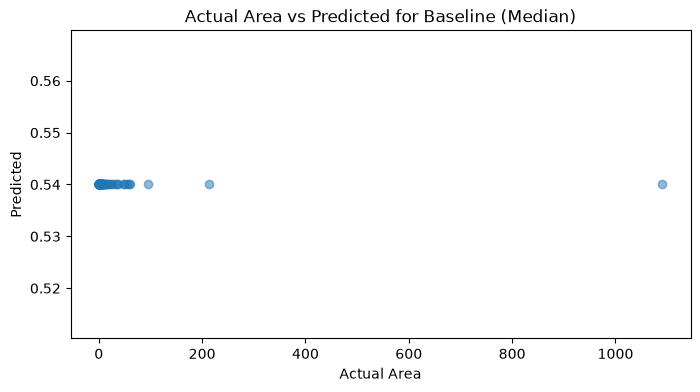

53
0.891757442581034
Time Taken ( Base Neural Network ):  0.18450546264648438


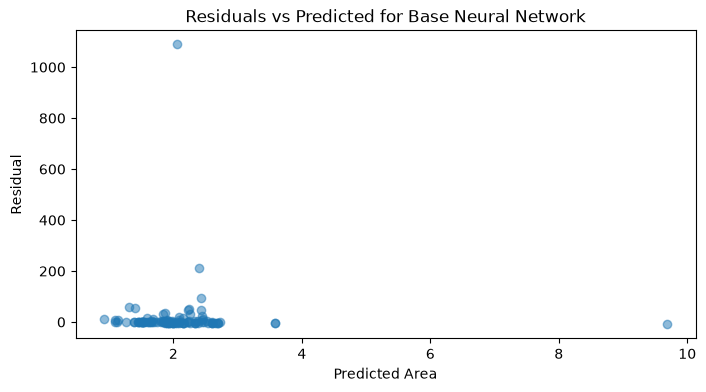

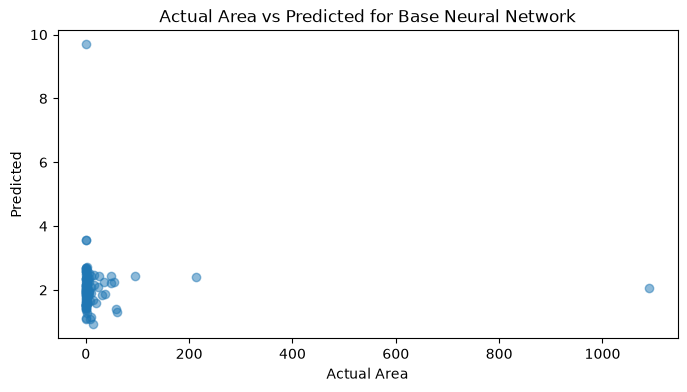

21
1.0022074412989221
Time Taken ( More layers ):  0.1816396713256836


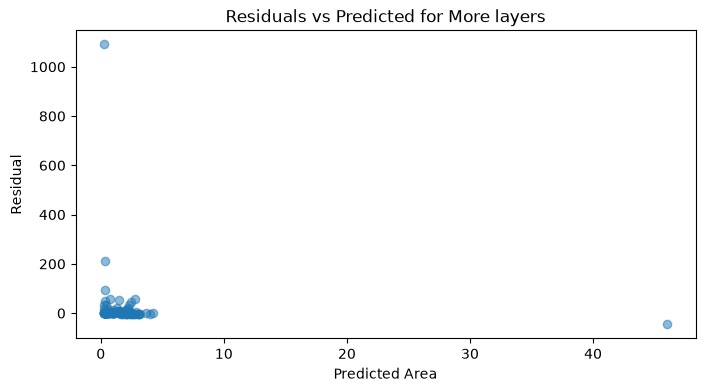

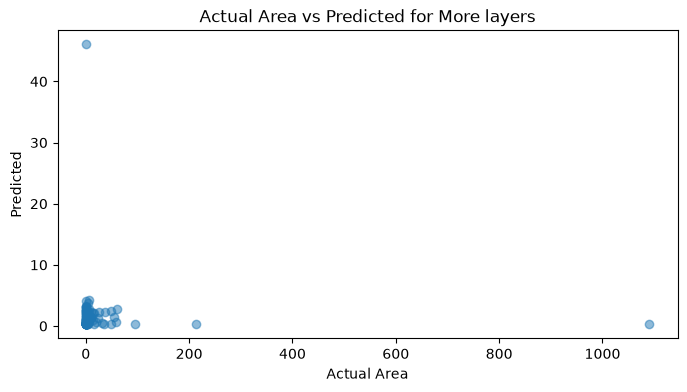

170
0.9102786428538131
Time Taken ( Sgd ):  0.4240405559539795


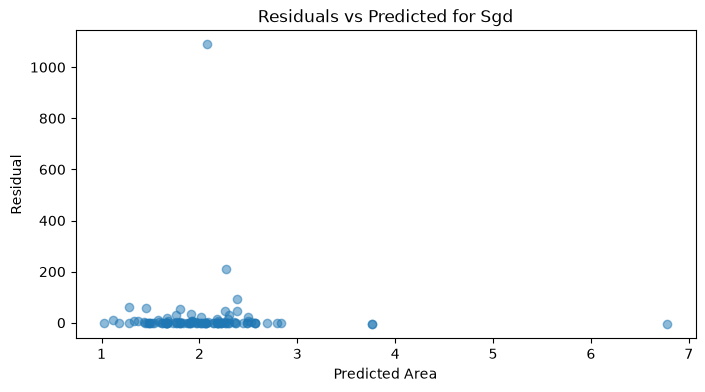

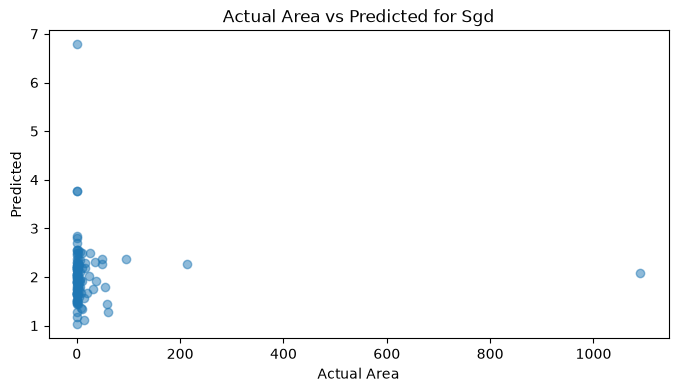

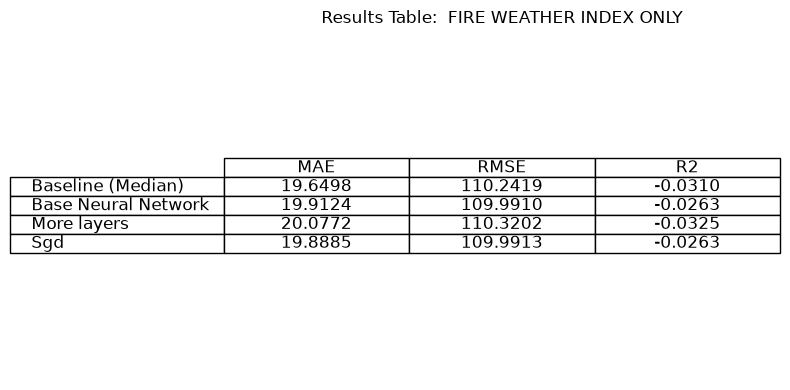

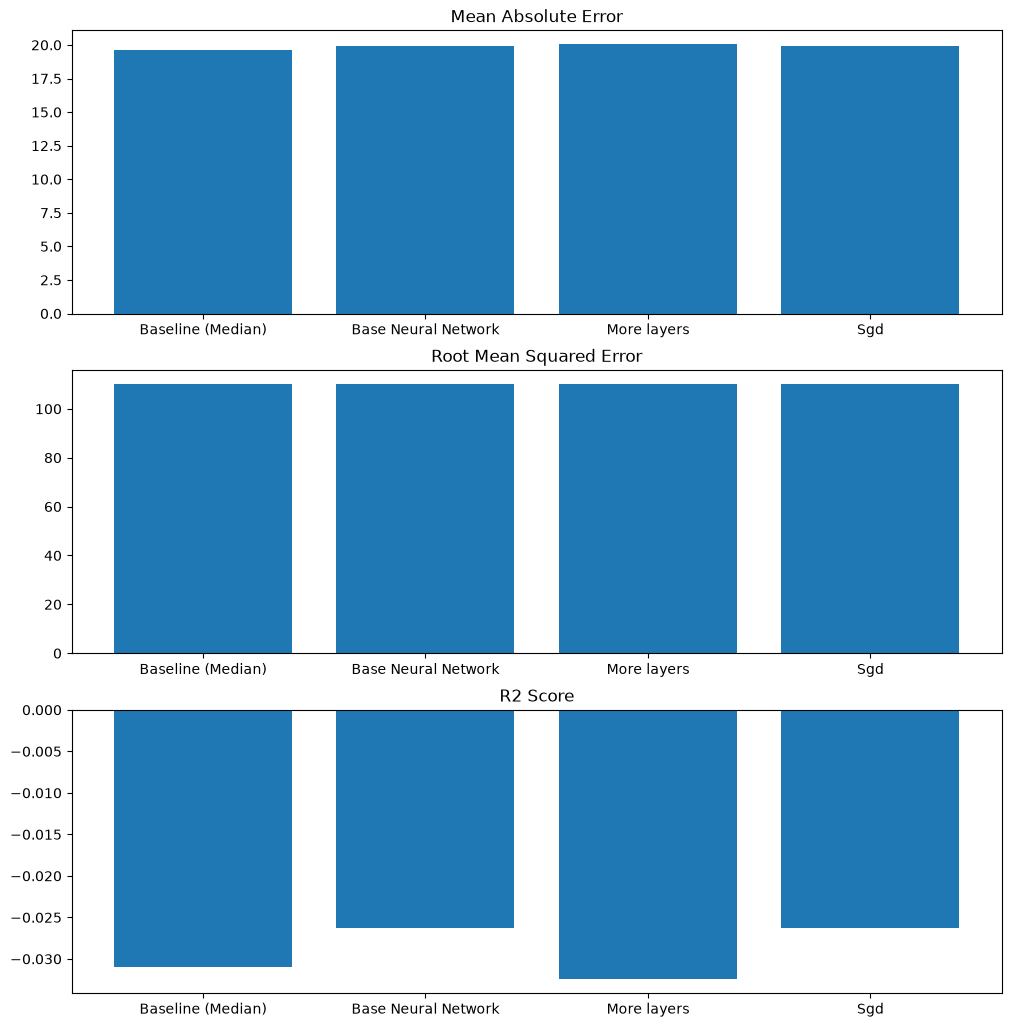

--------------PREPROCESSING:  VERY PRUNED (TEST) --------------
Time Taken ( Baseline (Median) ):  0.030975818634033203


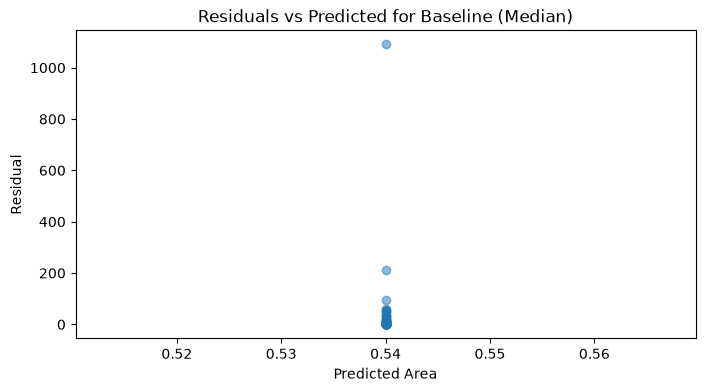

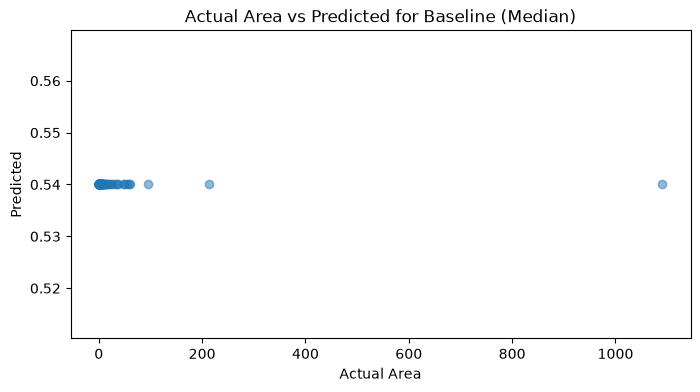

25
0.9314925553844788
Time Taken ( Base Neural Network ):  0.1017758846282959


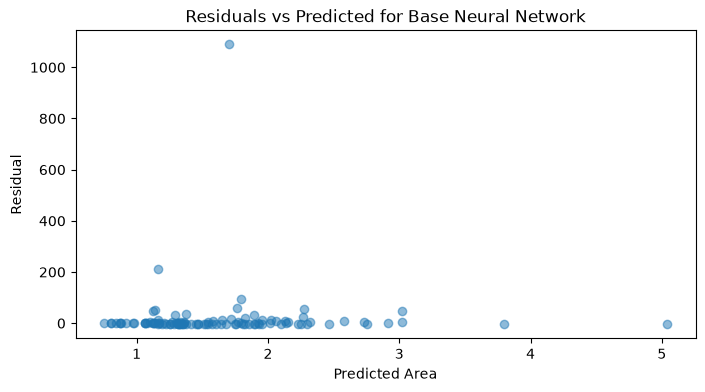

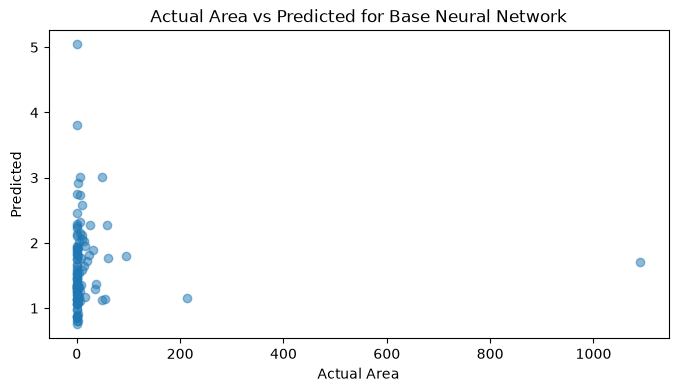

20
0.8747389483826975
Time Taken ( More layers ):  0.676344633102417


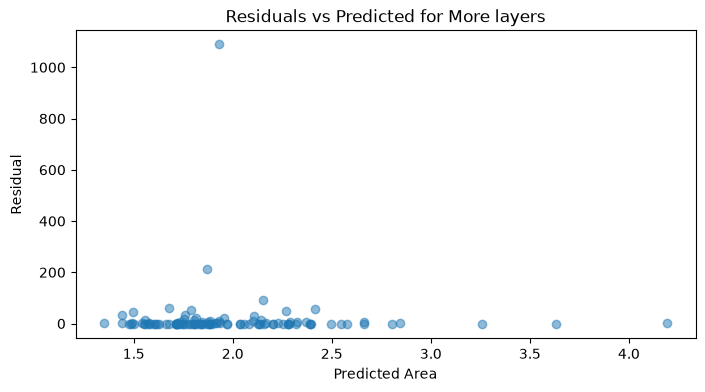

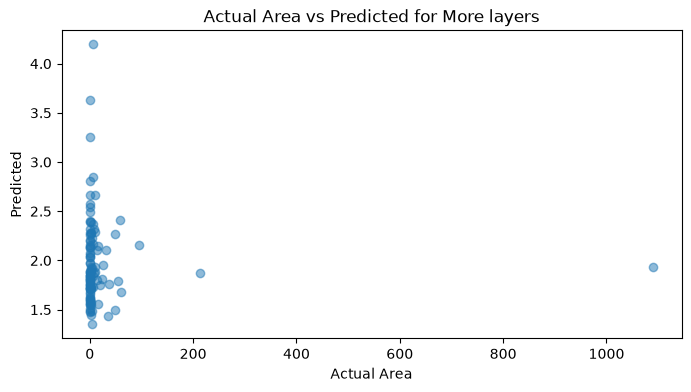

35
0.9553790169286439
Time Taken ( Sgd ):  0.12051606178283691


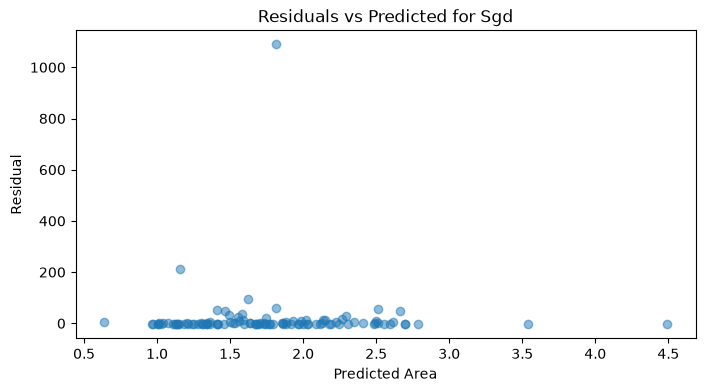

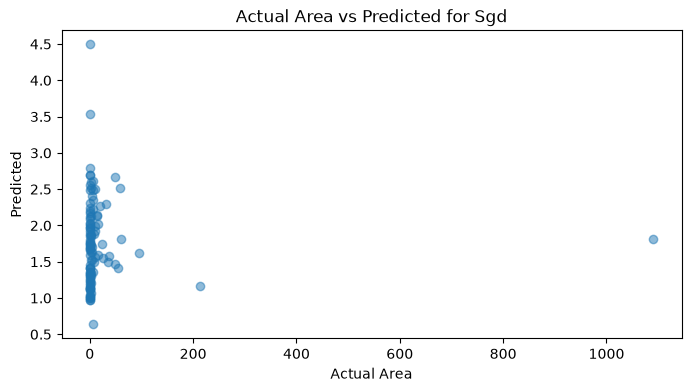

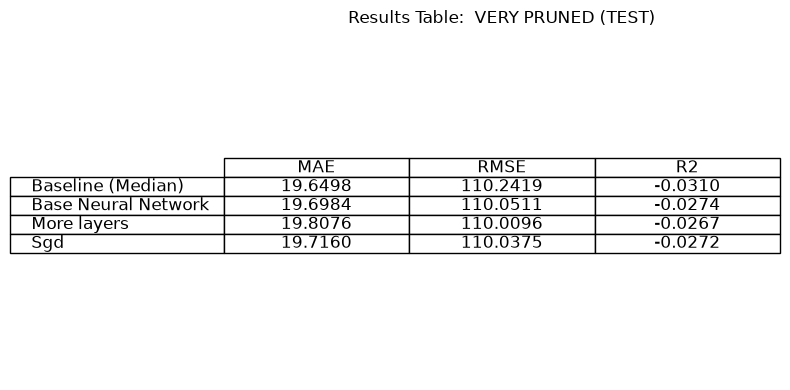

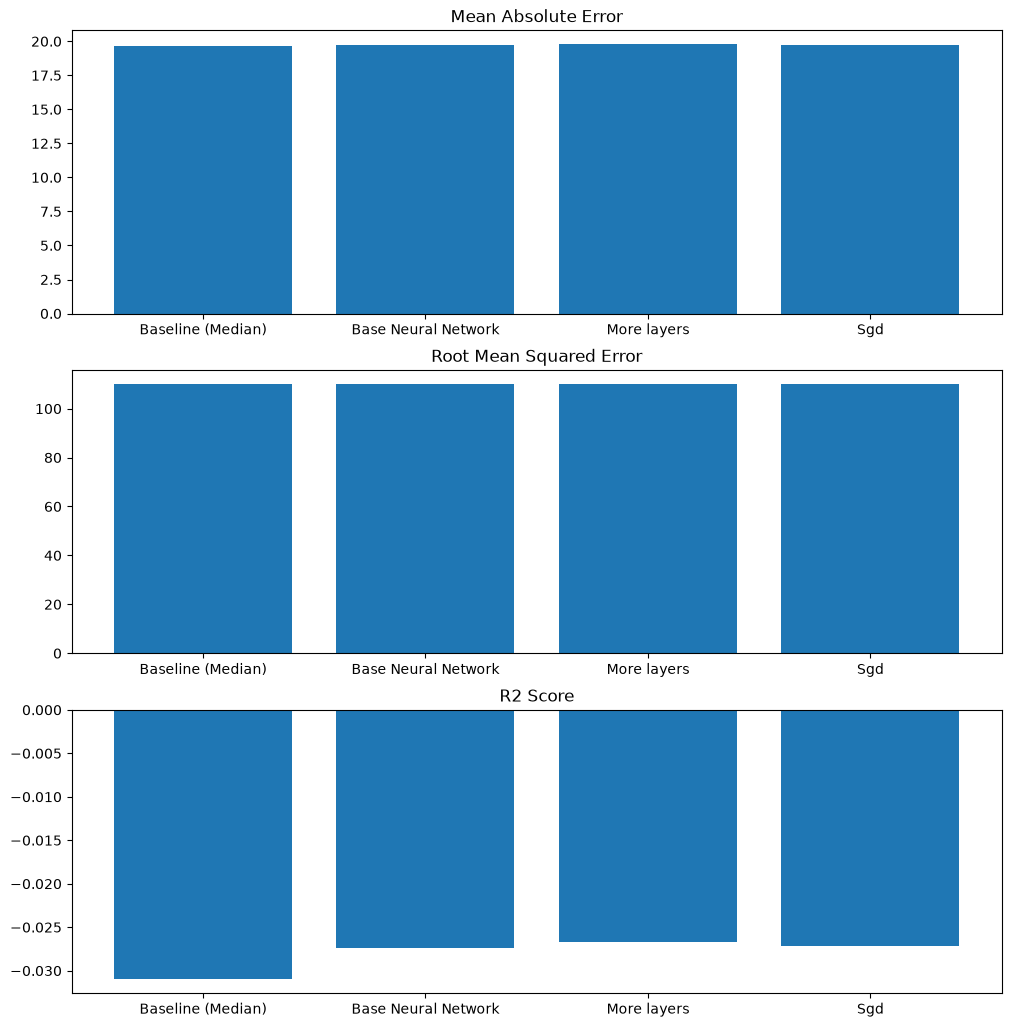

In [20]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

X = df[categorical_columns + numerical_columns]
y = df["area"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=RANDOM_STATE)

models = {
    "Baseline (Median)" : DummyRegressor(strategy="median"),
    "Base Neural Network" : MLPRegressor(hidden_layer_sizes=(64, 32),activation="relu", solver="adam",alpha=1e-4, early_stopping=True,max_iter=500, random_state=RANDOM_STATE),
    "More layers" : MLPRegressor(hidden_layer_sizes=(128, 64, 32, 16),activation="relu", solver="adam",alpha=1e-4, early_stopping=True,max_iter=500, random_state=RANDOM_STATE),
    "Sgd" : MLPRegressor(hidden_layer_sizes=(64, 32),activation="relu", solver="sgd",alpha=1e-4, early_stopping=True,max_iter=500, random_state=RANDOM_STATE),
}


for title, preprocessing in preprocessing_pipelines.items():
    print("--------------PREPROCESSING: ", title,"--------------")

    resultsMAE =[]
    resultsRMSE = []
    resultsR2 = []

    for name, model in models.items():
        
        model = make_pipeline(preprocessing, model)
        
        start_time = time.time()
        
        model.fit(X_train, np.log1p(y_train))
        pred = np.expm1(model.predict(X_test))

        elapsed_time = time.time() - start_time

        
        mae = mean_absolute_error(y_test, pred)
        rmse = root_mean_squared_error(y_test, pred)
        r2 = r2_score(y_test, pred)
        residuals = (y_test - pred)

        if name != "Baseline (Median)":
            fitted = model.named_steps["mlpregressor"]
            print(fitted.n_iter_)
            print(fitted.loss_)
            
        print("Time Taken (", name, "): ", elapsed_time)

        ## Plot Residual vs Predicted Area
        plt.figure(figsize={8,4})
        plt.scatter(pred, residuals, alpha=0.5)
        plt.xlabel("Predicted Area")
        plt.ylabel("Residual")
        plt.title(f"Residuals vs Predicted for {name}")

        plt.show()

        ## Plot Actual vs Predicted Areas
        plt.figure(figsize={8,4})
        plt.scatter(y_test, pred, alpha=0.5)
        plt.xlabel("Actual Area")
        plt.ylabel("Predicted")
        plt.title(f"Actual Area vs Predicted for {name}")

        plt.show()
        
        resultsMAE.append(mae)
        resultsRMSE.append(rmse)
        resultsR2.append(r2)

    #Plot Results
    model_names = list(models.keys())
    plt.figure(figsize={8, 2 + len(model_names)*0.5})
    plt.axis("off")
    columns = ["MAE", "RMSE", "R2"]
    text = []
    for i in range(len(model_names)):
        text.append([f"{resultsMAE[i]:.4f}",f"{resultsRMSE[i]:.4f}",f"{resultsR2[i]:.4f}"])
    
    table = plt.table(
        cellText = text,
        rowLabels = model_names,
        colLabels = columns,
        loc="center",
        cellLoc="center"
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    plt.title(f"Results Table:  {title}")
    plt.tight_layout()
    plt.show
    
    plt.figure(figsize={12,0.5+len(model_names) * 3}) ##Figure is dynamically sized to allow for more models to be added as needed


    plt.subplot(311, title="Mean Absolute Error").bar(range(len(resultsMAE)),resultsMAE)
    plt.xticks(range(len(model_names)),model_names)
    
    plt.subplot(312, title="Root Mean Squared Error").bar(range(len(resultsRMSE)),resultsRMSE)
    plt.xticks(range(len(model_names)),model_names)
    
    plt.subplot(313, title="R2 Score").bar(range(len(resultsR2)),resultsR2)
    plt.xticks(range(len(model_names)),model_names)

    plt.show()
